<a href="https://colab.research.google.com/github/baubyte/aprendizaje-por-refuerzo/blob/main/semana-07/UGR_AR_2_MonteCarloOpenAIGym_BJ1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Prof. Guadalupe Pascal

Prof. Julián E. Tornillo

-----------------------------------------------
# Monte Carlo con OpenAI Gym

En este notebook se desarrolla un ejemplo que recorre los principales conceptos sobre el método Monte Carlo para simulación, Aplicado en el Aprendizaje por Refuerzo.


Se aborda el ejemplo ***Black Jack***

https://gymnasium.farama.org/environments/toy_text/blackjack/ de la librería OpenAI Gym (https://gymnasium.farama.org/)

##Monte Carlo (Breve repaso)

Esta familia de algoritmos se utiliza cuando no conocemos todos los elementos de los procesos de decisión de Markov (MDP), particularmente la función de transición y la función de recompensa.

**{S,A,<font color="red">p,R</font>,$\gamma$}**

De esta manera, no es posible utilizar las ecuaciones de Bellman. Entonces, volvemos a la función estado-valor tradicional:

$V_\pi(s) = \mathbb{E}_\pi \left[ \sum_{k=0}^{\infty} ɣ^k \cdot R_{t+k+1} \; \middle| \; S_t = s\right]$

y acción valor tradicional:


$Q_\pi(s, a) = \mathbb{E}_\pi \left[ \sum_{k=0}^{\infty} ɣ^k \cdot R_{t+k+1} \; \middle| \; S_t = s,A_t = a\right]$


Los métodos Monte Carlo en aprendizaje por refuerzo permiten estimar el valor de estados o acciones como la recompensa esperada a largo plazo, a partir de la observación de episodios completos de interacción con el entorno, sin necesidad de conocer el modelo subyacente (es decir, las funciones de transición 𝑃 ni de recompensa 𝑅). Estos algoritmos se basan exclusivamente en la experiencia empírica y actualizan sus estimaciones únicamente al finalizar cada episodio, constituyéndose como una estrategia efectiva para resolver Procesos de Decisión de Markov (MDP) mediante el aprendizaje de funciones de valor o políticas basadas en promedios de retornos observados.

En otras palabras, Utilizando Monte Carlo, el agente aprende sobre la base de a experiencia (prueba y error). Esto se traduce en la evaluación de múltiples interacciones del agente con el entorno (Simulación)

Desde la teoría, se debería generar un número infinito de interacciones. Como eso no es factible desde la realidad, obtendremos una estimación sobre la base de un número finito de interacciones.


*   Si se utiliza la función **estado-valor**, se obtiene una evaluación de la política. Con Monte Carlo, lo llamaremos **Prediccón**.
*   Si se utiliza la función **acción-valor**, se obtiene una política óptima. Con Monte Carlo, lo llamaremos **Control**




EJEMPLO:
Supongamos que entrenás a un agente a jugar al ajedrez:

* El MDP describe el juego: reglas, estados (tableros), acciones (movimientos), y recompensas (ganar/perder).

* El algoritmo Monte Carlo observa partidas completas y aprende que ciertas posiciones llevan más frecuentemente a la victoria.





## Entorno

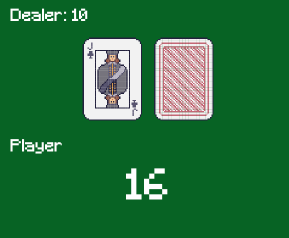

In [1]:
# Se requiere la versión 0.17.3 de OpenAI Gym para poder
# usar el método "render". Versiones más recientes no
# permiten usar este método desde Google Colab
!pip install gym==0.17.3

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 8.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 8.6 MB/s eta 0:00:00
  Created wheel for gym: filename=gym-0.17.3-py3-none-any.whl size=1654678 sha256=c4ddadc9567c96165d31a98efeef0a3456cd4e4cf081603e3bee5c13152968a3
  Stored in directory: /root/.cache/pip/wheels/28/27/f2/dcf9709f42d57a6a8c43578a5eebb50d95e1a3a9811621f75e
Successfully built gym
  Attempting uninstall: cloudpickle
    Found existing installation: cloudpickle 3.1.2
    Uninstalling cloudpickle-3.1.2:
      Successfully uninstalled cloudpickle-3.1.2
  Attempting uninstall: gym
    Found existing installation: gym 0.25.2
    Uninstalling gym-0.25.2:
      Successfully uninstalled gym-0.25.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask 2026.8.0 requires cloudpickle>=3.

###BlackJack



**Objetivo del juego**

El Blackjack es un popular juego de cartas donde el objetivo es obtener un puntaje lo más cercano a 21 pero sin pasarse.

Cada una de las figuras (J, Q y K) tiene un puntaje de 10, mientras que el As puede valer 1 o 11 y cada una de las cartas restantes tiene un puntaje igual al valor numérico que aparezca en la carta.

**¿Cómo se juega?**

En su mínima expresión, existe un jugador y un crupier (quien reparte las cartas). El juego comienza con dos cartas, ambas repartidas boca arriba para el jugador y una boca arriba y otra boca abajo para el crupier.

*Posibles situaciones:*

El jugador obtiene 21 inmediatamente (As + J/Q/K) y el crupier no. El jugador gana.
El jugador obtiene 21 inmediatamente pero el crupier también. Empate
El jugador NO obtiene 21 inmediatamente. Dependiendo de la suma puede:
"pedir" más cartas
"plantarse", es decir no solicitar más cartas
"pasarse", es decir cuando la suma de las cartas que tiene supera 21. En este último caso el jugador pierde.
Si ni jugador ni crupier alcanzan 21, gana quien tenga las cartas con la suma más cercana a este valor.

*As usable y no usable*

Si el jugador tiene un As que podría contar como 11 sin pasarse, entonces se dice que tiene un "As usable". En este caso el As siempre contará como un 11.

Si el jugador tiene un As que al contarlo como 11 hace que se pase, entonces se dice que tiene un "As no usable". En este caso el As sumará sólo 1 para evitar perder.

###Preguntas iniciales

En el juego del BlackJack:

1.   ¿Cuáles son los componentes si se lo estudia desde el Aprendizaje por Refuerzo?
2.   ¿Cuál sería el objetivo?
3.   ¿Es posible utilizar los algoritmos de Programación Dinámica ya conocidos? ¿Por qué?

###Conociendo el entorno

In [2]:
import gym
import random
from collections import defaultdict

import numpy as np

import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap # Para colorear gráficos

from tabulate import tabulate # Para tablas


env = gym.make('Blackjack-v0')

In [3]:
# Espacio discreto con 2 acciones: (Pedir carta o plantarse)
env.action_space

Discrete(2)

In [4]:
# Espacio de estados: cada estado será una tupla que contendrá:
#   La suma actual del jugador (agente): (0 a 31)


#   La carta descubierta del "crupier": (1 a 11)


#   Si el agente tiene o no un As usable: (True, False)



env.observation_space

Tuple(Discrete(32), Discrete(11), Discrete(2))

In [5]:
# Por ejemplo, para jugar un episodio (una mano):

estado = env.reset()
while True:
    # Mostrar las cartas del crupier y del jugador
    print(f'Cartas del crupier: {env.dealer}')
    print(f'Cartas del jugador: {env.player}')

    print('-'*60)
    # Imprimir estado:
    print(f'Estado: {estado}:')
    print(f'\tSuma: {estado[0]}')
    print(f'\tCarta descubierta crupier: {estado[1]}')
    print(f'\t¿El jugador tiene un as usable?: {estado[2]}')

    print('-'*60)
    accion = env.action_space.sample()
    if accion == 1: # accion = "pedir"
        print('Acción: seguir jugando')
    else: # accion = "plantarse"
        print('Acción: plantarse')

    print('-'*60)
    # Ejecutar jugada
    estado, recompensa, done, info = env.step(accion) #Estado, recompensa y si termina el juego
    if done:
        print(f'Fin del juego. Recompensa: {recompensa}')
        if recompensa > 0:
            print('¡Ganaste!')
        else:
            print('Perdiste')
        break

Cartas del crupier: [8, 6]
Cartas del jugador: [10, 8]
------------------------------------------------------------
Estado: (18, 8, False):
	Suma: 18
	Carta descubierta crupier: 8
	¿El jugador tiene un as usable?: False
------------------------------------------------------------
Acción: seguir jugando
------------------------------------------------------------
Fin del juego. Recompensa: -1.0
Perdiste


##Predicción

Comenzaremos viendo cómo usar la predicción con Monte Carlo para evaluar la política del agente.

El objetivo es cómo encontrar la función estado-valor $V_\pi(s)$ para evaluar la política.

Existen dos variantes principales:


*   **Múltiples visitas**

En el ejemplo del lago congelado, permitiríamos que el agente transite más de una vez por el mismo estado

*   **Primera visita**

En el ejemplo del lago congelado, solo consideraríamos la primera visita a cada estado

---------------------------------------------------------------------------


En este caso, utilizamos el algoritmo de primera visita para evaluar qué tan buenas son dos políticas:

1. Política 1: totalmente aleatoria
2. Política 2: el jugador se planta siempre que la suma de sus cartas sea mayor a 18

In [6]:
def politica1(s):
    '''Política aleatoria'''
    return random.randint(0,1) #0=plantarse y 1=pedir



#   La suma actual del jugador (agente)
#   La carta descubierta del "crupier"
#   Si el agente tiene o no un As usable (True, False)

def politica2(s, umbral=18):
    suma, carta_croupier, as_usable = s
    if suma > umbral:
        return 0 # plantarse
    else:
        return 1 # pedir



Crearemos una función para generar un episodio:

In [7]:
def generar_episodio(ent, pi):
    episodio = []
    done = True
    while True:
        if done:
            St, Rt, done = ent.reset(), None, False
        else: # Hacer que el agente interactúe con el entorno
            St, Rt, done, info = ent.step(At)

        # Generar acción y añadir trayectoria a listado de episodios
        At = pi(St)
        episodio.append((St, Rt, done, At))

        if done:
            break

    return episodio, len(episodio)-1

In [8]:
# Prueba (politica1) de la función (T: time-steps del episodio)
episodio, T = generar_episodio(env, politica1)
print(f'Episodio: {episodio}')
print(f'Time steps del episodio: {T}')

print('-'*60)

# Crear una lista de listas para los datos de la tabla
tabla_datos = [(str(estado), str(accion), str(finalizado), str(recompensa)) for estado, recompensa, finalizado, accion in episodio]

headers = ["Estado", "Acción", "Finalizado", "Recompensa"]

# Utilizar tabulate para mostrar los datos en forma de tabla
table = tabulate(tabla_datos, headers, tablefmt="grid")

print("Episodio:")
print(table)
print(f'Time steps del episodio: {T}')


Episodio: [((13, 7, False), None, False, 1), ((23, 7, False), -1.0, True, 1)]
Time steps del episodio: 1
------------------------------------------------------------
Episodio:
+----------------+----------+--------------+--------------+
| Estado         |   Acción | Finalizado   | Recompensa   |
+================+==========+==============+==============+
| (13, 7, False) |        1 | False        | None         |
+----------------+----------+--------------+--------------+
| (23, 7, False) |        1 | True         | -1.0         |
+----------------+----------+--------------+--------------+
Time steps del episodio: 1


Ahora sí implementamos el algoritmo de predicción con Monte Carlo de primera visita

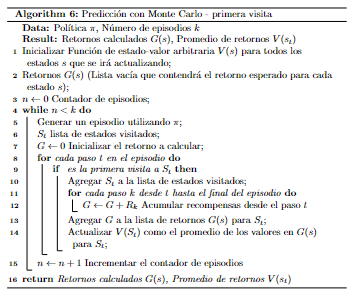

---
**Algorithm 6:** Predicción con Monte Carlo - primera visita
---
**Data:** Política $\pi$, Número de episodios $k$  
**Result:** Retornos calculados $G(s)$, Promedio de retornos $V(s_t)$  
***

**1** Inicializar Función de estado-valor arbitraria $V(s)$ para todos los estados $s$ que se irá actualizando;  
**2** Retornos $G(s)$ (Lista vacía que contendrá el retorno esperado para cada estado $s$);  
**3** $n \leftarrow 0$ Contador de episodios;  
**4** **while** $n < k$ **do**  
> **5** Generar un episodio utilizando $\pi$;  
> **6** $S_t$ lista de estados visitados;  
> **7** $G \leftarrow 0$ Inicializar el retorno a calcular;  
> **8** **for** *cada paso $t$ en el episodio* **do**  
>> **9** **if** *es la primera visita a $S_t$* **then**  
>>> **10** Agregar $S_t$ a la lista de estados visitados;  
>>> **11** **for** *cada paso $k$ desde $t$ hasta el final del episodio* **do**  
>>>> **12** $G \leftarrow G + R_k$ Acumular recompensas desde el paso $t$  
>>>
>>> **13** Agregar $G$ a la lista de retornos $G(s)$ para $S_t$;  
>>> **14** Actualizar $V(S_t)$ como el promedio de los valores en $G(s)$ para $S_t$;  
>
> **15** $n \leftarrow n + 1$ Incrementar el contador de episodios  

**16** **return** *Retornos calculados $G(s)$, Promedio de retornos $V(s_t)$*  

---

In [9]:
def prediccion_MC_primera_visita(ent, pi, neps, gamma):
    V = {} # Función estado-valor (resultado de la predicción)
    Retornos = defaultdict(list) # Por defecto para cada estado será una lista vacía

    for ep in range(neps):
        episodio, T = generar_episodio(ent, pi)
        G = 0 # Acumulador retornos
        #for t in range(T-1,-1,-1): # por cada interacción (time-step)
        for t in reversed(range(T)): # por cada interacción (time-step)
            # Extraer estado, recompensa y acción en "t"
            St, _, _, At = episodio[t]

            # Extraer recompensa en t+1
            _, Rt1, _, _ = episodio[t+1]

            # Actualizar retorno
            G = gamma*G + Rt1

            # Incluir y promediar sólo si es primera visita
            for i in range(0,t):
                if St not in episodio[i][0]:
                    Retornos[St].append(G)
                    V[St] = np.average(Retornos[St])

    return V, Retornos

In [10]:
# Prueba de la función (usaremos gamma=1: nos interesa simplemente
# si gana o pierde, no el número de jugadas requeridas)
V, Returns = prediccion_MC_primera_visita(env, politica1, neps=10000, gamma=1)

In [11]:
# Resumen de los resultados en forma de tabla
resumen_resultados = []
for estado, retornos in Returns.items():
    promedio_retornos = np.mean(retornos)
    resumen_resultados.append((estado, promedio_retornos))

# Encabezados de columna
headers = ["Estado", "Promedio de Retornos"]


# Utilizar tabulate para mostrar los datos en forma de tabla
table = tabulate(resumen_resultados, headers, tablefmt="grid")

#TABLA PARA MOSTRAR SOLO LOS PRIMEROS 20 RESULTADOS
table20 = tabulate(resumen_resultados[:20], headers, tablefmt="grid")

print("Resumen de Resultados politica1: primeros 20")
print(table20)

Resumen de Resultados politica1: primeros 20
+-----------------+------------------------+
| Estado          |   Promedio de Retornos |
+=================+========================+
| (20, 1, False)  |             -0.514286  |
+-----------------+------------------------+
| (21, 10, False) |             -0.113402  |
+-----------------+------------------------+
| (20, 8, False)  |             -0.0769231 |
+-----------------+------------------------+
| (19, 4, False)  |             -0.32      |
+-----------------+------------------------+
| (14, 10, False) |             -0.641304  |
+-----------------+------------------------+
| (21, 3, False)  |             -0.255814  |
+-----------------+------------------------+
| (19, 2, False)  |             -0.341463  |
+-----------------+------------------------+
| (19, 6, False)  |             -0.575     |
+-----------------+------------------------+
| (21, 6, True)   |              0.75      |
+-----------------+------------------------+
| (8, 5, F

Función para graficar la función estado-valor obtenida:

In [37]:
def graficar_funcion_valor(V, titulo=''):
    """Grafica la función estado-valor en superficies 3D para As usable y As no usable."""

    def obtener_rango_ejes(V):
        # Determina los límites mínimos y máximos de la suma del jugador y la carta del crupier
        suma_jugador = [k[0] for k in V.keys()]
        carta_crupier = [k[1] for k in V.keys()]

        x_valores = np.arange(min(suma_jugador), max(suma_jugador) + 1)
        y_valores = np.arange(min(carta_crupier), max(carta_crupier) + 1)

        # Crea la rejilla de coordenadas X e Y
        return np.meshgrid(x_valores, y_valores)

    def construir_matriz_Z(X, Y, as_usable):
        # Crea una matriz Z con los valores correspondientes al estado (suma, crupier, as_usable)
        Z = np.zeros(X.shape)
        for i in range(X.shape[0]):
            for j in range(X.shape[1]):
                estado = (X[i, j], Y[i, j], as_usable)
                Z[i, j] = V.get(estado, 0.0) # Retorna 0.0 si el estado no fue visitado
        return Z

    def dibujar_superficie(ax, as_usable, subtitulo):
        # Genera los datos de los ejes
        X, Y = obtener_rango_ejes(V)
        Z = construir_matriz_Z(X, Y, as_usable)

        # Configura y dibuja la superficie 3D
        ax.plot_surface(X, Y, Z, rstride=1, cstride=1, cmap=plt.cm.RdYlGn, vmin=-1, vmax=1)
        ax.set_title(subtitulo)
        ax.set_xlabel('Suma cartas del jugador', fontsize=8)
        ax.set_ylabel('Carta descubierta crupier', fontsize=8)
        ax.set_zlabel('Valor del estado', fontsize=8)
        ax.view_init(ax.elev, -120)

    # Inicializa la figura principal con dos subgráficas 3D
    fig = plt.figure(figsize=(12, 5))
    fig.suptitle(titulo, fontsize=16)

    # Panel Izquierdo: As Usable
    ax_usable = fig.add_subplot(121, projection='3d')
    dibujar_superficie(ax_usable, as_usable=True, subtitulo='As usable')

    # Panel Derecho: As No Usable
    ax_no_usable = fig.add_subplot(122, projection='3d')
    dibujar_superficie(ax_no_usable, as_usable=False, subtitulo='As no usable')

    plt.show()

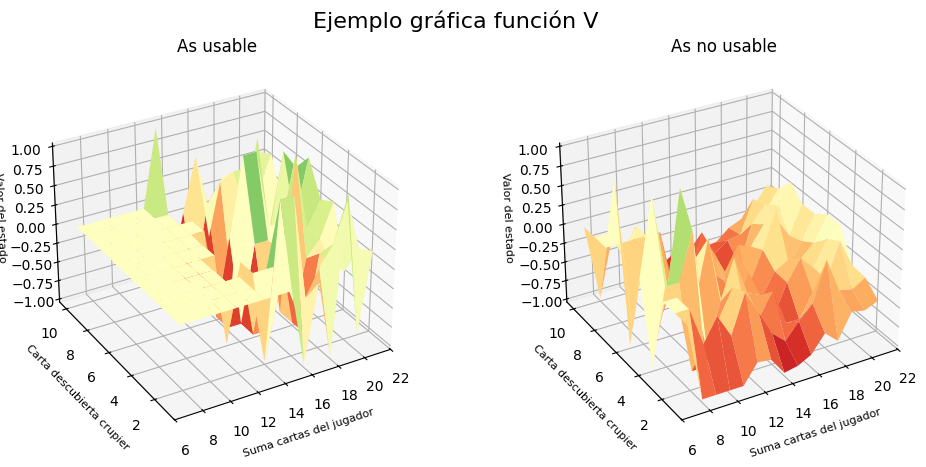

In [43]:
graficar_funcion_valor(V,'Ejemplo gráfica función V')

Hacemos el mismo procedimiento con la politica2 (plantarse con 18)

In [14]:
# Prueba de la función (usaremos gamma=1: nos interesa simplemente
# si gana o pierde, no el número de jugadas requeridas, sin penalizar por más jugadas)
V2, Returns2 = prediccion_MC_primera_visita(env, politica2, neps=10000, gamma=1)

In [15]:
# Resumen de los resultados en forma de tabla
resumen_resultados2 = []
for estado, retornos2 in Returns2.items():
    promedio_retornos2 = np.mean(retornos2)
    resumen_resultados2.append((estado, promedio_retornos2))

# Encabezados de columna
headers = ["Estado", "Promedio de Retornos"]


# Utilizar tabulate para mostrar los datos en forma de tabla
table_2 = tabulate(resumen_resultados2, headers, tablefmt="grid")

#TABLA PARA MOSTRAR SOLO LOS PRIMEROS 20 RESULTADOS
table20_2 = tabulate(resumen_resultados2[:20], headers, tablefmt="grid")

print("Resumen de Resultados: primeros 20")
print(table20_2)

Resumen de Resultados: primeros 20
+-----------------+------------------------+
| Estado          |   Promedio de Retornos |
+=================+========================+
| (15, 10, False) |              -0.605932 |
+-----------------+------------------------+
| (21, 6, False)  |               0.840426 |
+-----------------+------------------------+
| (17, 4, False)  |              -0.662791 |
+-----------------+------------------------+
| (18, 10, False) |              -0.660167 |
+-----------------+------------------------+
| (15, 2, False)  |              -0.516129 |
+-----------------+------------------------+
| (21, 7, False)  |               0.963303 |
+-----------------+------------------------+
| (17, 7, False)  |              -0.4375   |
+-----------------+------------------------+
| (20, 9, False)  |               0.596491 |
+-----------------+------------------------+
| (17, 2, False)  |              -0.780488 |
+-----------------+------------------------+
| (13, 2, False)  | 

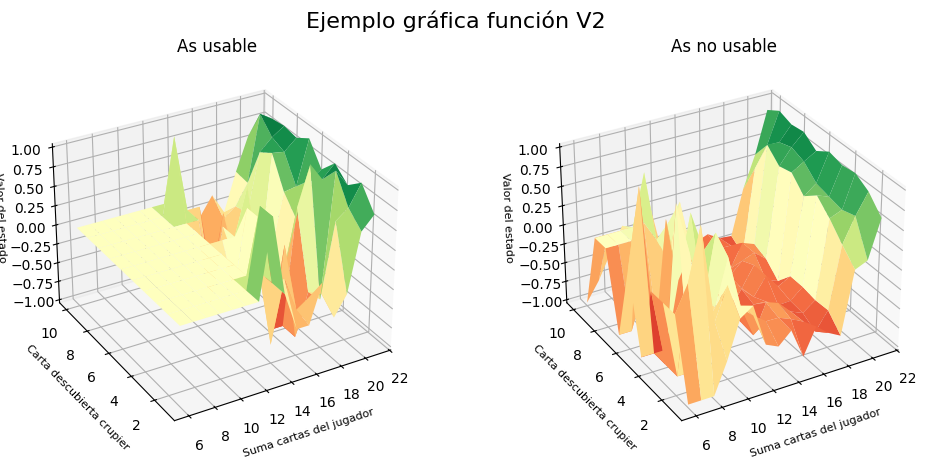

In [16]:
graficar_funcion_valor(V2,'Ejemplo gráfica función V2')


#IQUIERDA: AS USABLE                                      #DERECHA: AS NO USABLE

Comparemos las dos políticas (política1: aleatoria, política2: plantarse al alcanzar una suma de 18) usando el mismo número de episodios: En este caso: 50.000 episodios.

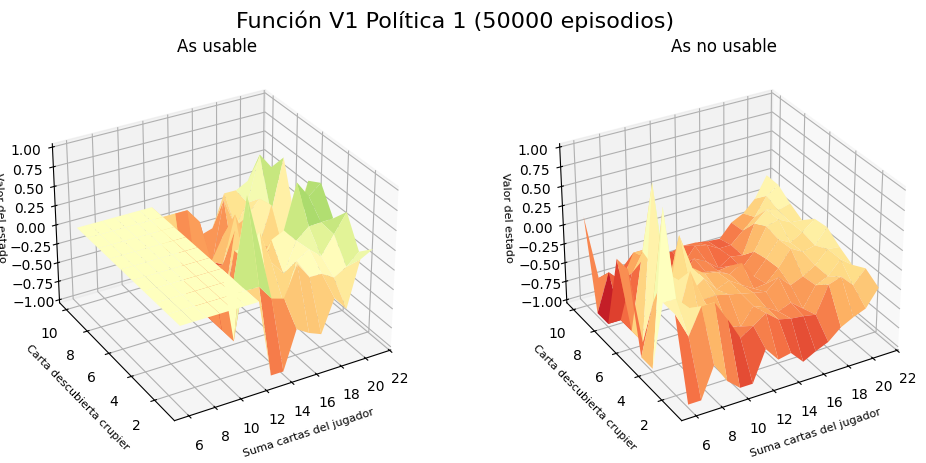

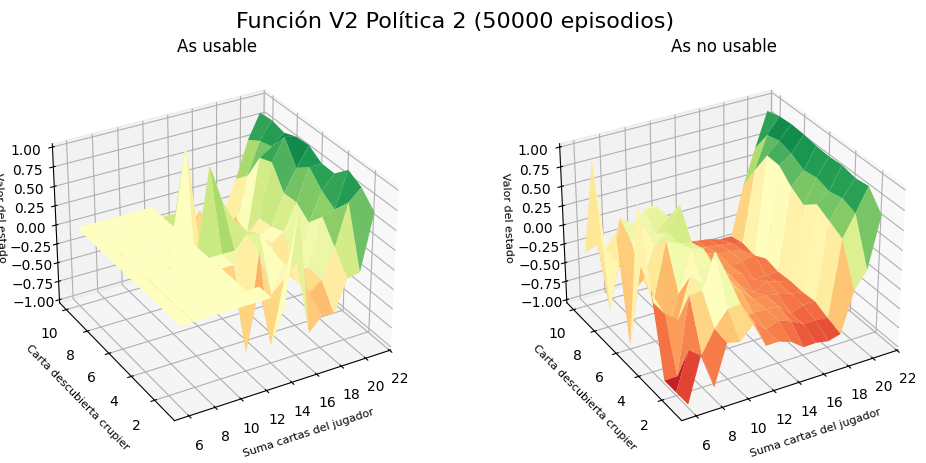

In [17]:
V1_50000, _ = prediccion_MC_primera_visita(env, politica1, neps=50000, gamma=1)
V2_50000, _ = prediccion_MC_primera_visita(env, politica2, neps=50000, gamma=1)
graficar_funcion_valor(V1_50000,'Función V1 Política 1 (50000 episodios)')
graficar_funcion_valor(V2_50000,'Función V2 Política 2 (50000 episodios)')

Es evidente que la política 2 genera valores más altos

¿Cómo interpretamos estos resultados? Si nos enfocamos por ejemplo en la gráfica "As no usable" de la política 2, vemos que la porción en rojo está asociada a bajos valores de estado, es decir **bajas probabilidades de éxito**, mientras que la porción verde corresponde a valor de estados altos (cercanos a 1) y por tanto **altas probabilidades de éxito**.

Por ejemplo, si el estado es (Suma=20, carta descubierta crupier=8, As no usable) la probabilidad de éxito es cercana al 75% usando esta política.

In [18]:
# Comparación cuantitativa
diferencias_V1_V2 = []
for estado, valor in V1_50000.items():
    if estado in V2_50000:
        diferencia = V2_50000[estado] - valor
        diferencias_V1_V2.append(diferencia)

print(np.average(diferencias_V1_V2))

0.26005324677553143


En promedio, la política 2 es aproximadamente 22,44% mejor que la política 1

Veamos cómo influye el número de episodios en la estimación de la función estado-valor:

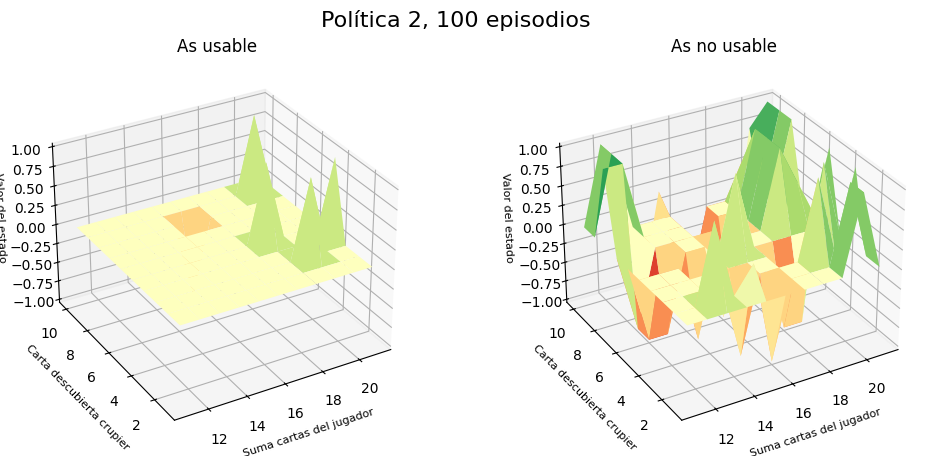

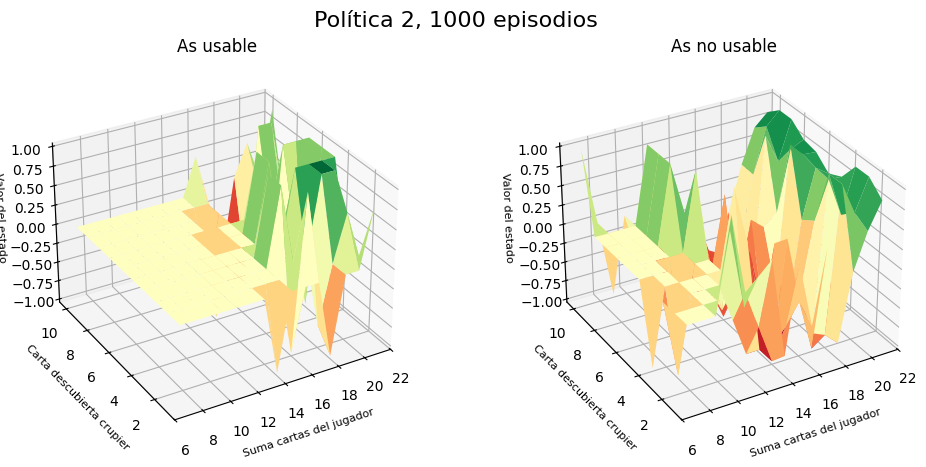

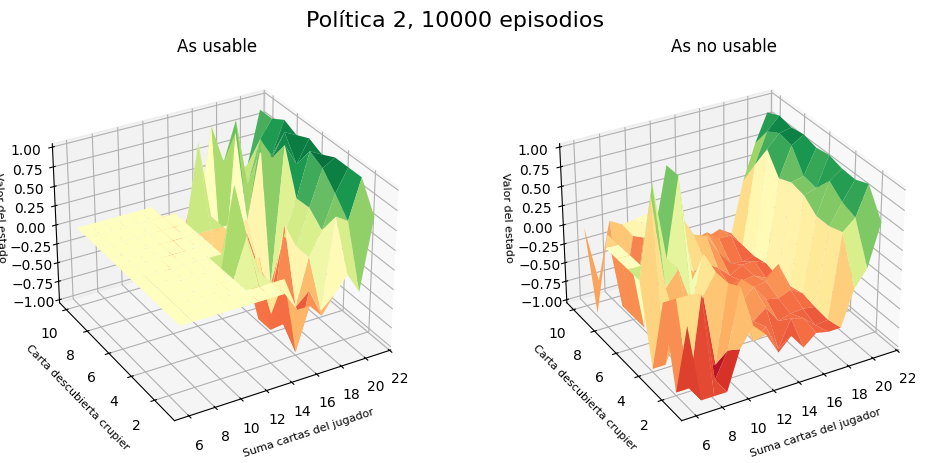

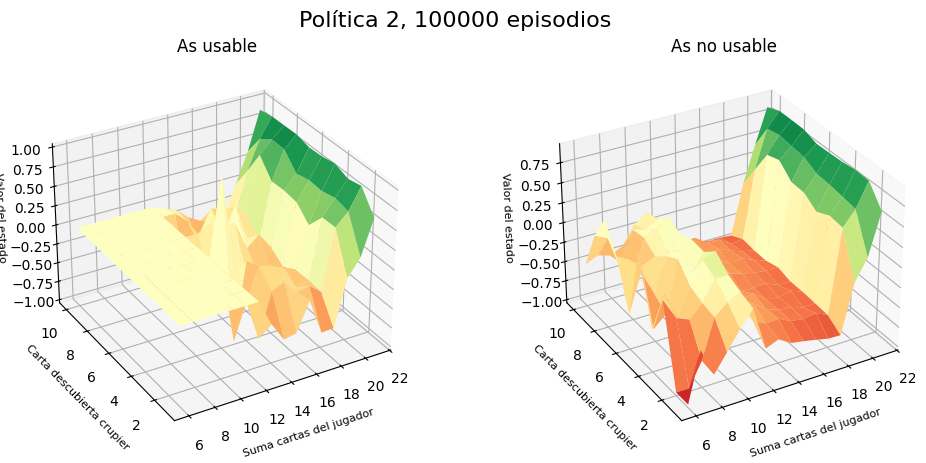

In [19]:
V2_100, _ = prediccion_MC_primera_visita(env, politica2, neps=100, gamma=1)
V2_1000, _ = prediccion_MC_primera_visita(env, politica2, neps=1000, gamma=1)
V2_10000, _ = prediccion_MC_primera_visita(env, politica2, neps=10000, gamma=1)
V2_100000, _ = prediccion_MC_primera_visita(env, politica2, neps=100000, gamma=1)

graficar_funcion_valor(V2_100,'Política 2, 100 episodios')
graficar_funcion_valor(V2_1000,'Política 2, 1000 episodios')
graficar_funcion_valor(V2_10000,'Política 2, 10000 episodios')
graficar_funcion_valor(V2_100000,'Política 2, 100000 episodios')

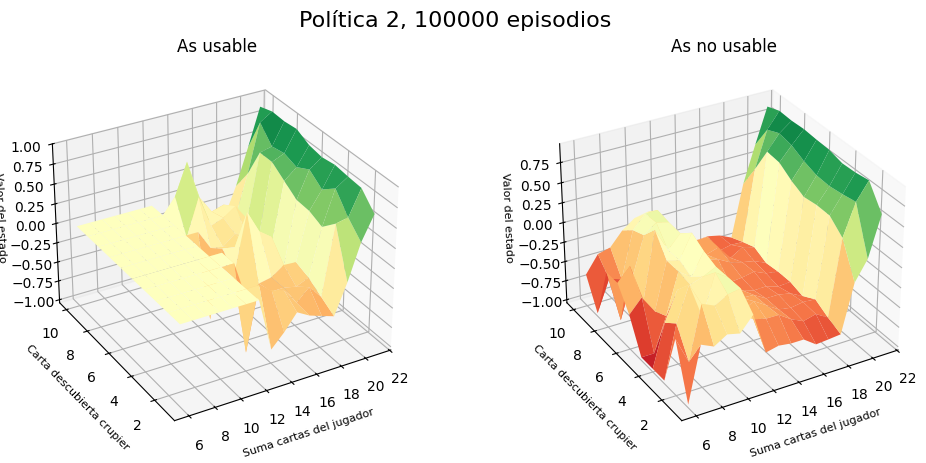

In [20]:
V2_100000, _ = prediccion_MC_primera_visita(env, politica2, neps=100000, gamma=1)

graficar_funcion_valor(V2_100000,'Política 2, 100000 episodios')

Es evidente que entre más episodios se generen mejor será la estimación. Comparar por ejemplo "As usable" con 100 episodios vs "As usable" con 100.000 episodios.

##Control

Se utiliza la función acción-vaor $Q_\pi(s, a)$ para encontrar una política óptima.

Se busca una combinación entre **Explotación y Exploración**


*   **Explotación:**

Tomamos la acción que maximiza la función:

$ \pi(a|s) = \arg\max_a Q_\pi(s, a)$

Desventaja: Al generar un número finito de escenarios, no podemos garantizar que se visiten todas las acciones posibles. De esta manera, la maximización de esta función no necesariamente es la mejor posible.


*   **Exploración:**

Escoger ua acción de manera aleatoria y comenzar a mejorar iterativamente

---------------------------------------------------------------------------
De esta manera surgen los algoritmos codiciosos o *$ \epsilon$ greedy* para balancear explotación y exploración.

---------------------------------------------------------------------------
**Tipos de control:**

*   on-policy:

Utilizamos la misma política que estamos optimizando para definir las acciones del agente

*   off-policy

Se utilizan dos políticas diferentes: una define el comportamiento del agente (cómo va a interactuar el agente con el entorno) y otra para optimizar iterativamente



###Control "on-policy"

Veamos ahora cómo entrenar el agente usando algoritmos de Control con Monte Carlo.


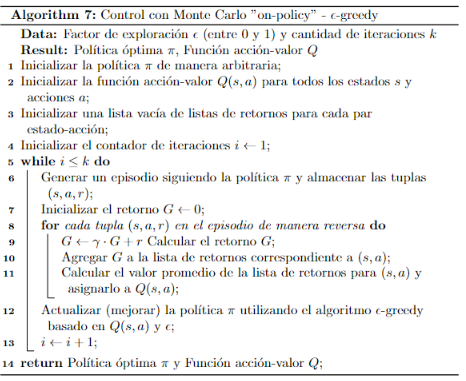

---
**Algorithm 7:** Control con Monte Carlo "on-policy" - $\epsilon$-greedy
---
**Data:** Factor de exploración $\epsilon$ (entre 0 y 1) y cantidad de iteraciones $k$  
**Result:** Política óptima $\pi$, Función acción-valor $Q$  
***

**1** Inicializar la política $\pi$ de manera arbitraria;  
**2** Inicializar la función acción-valor $Q(s, a)$ para todos los estados $s$ y acciones $a$;  
**3** Inicializar una lista vacía de listas de retornos para cada par estado-acción;  
**4** Inicializar el contador de iteraciones $i \leftarrow 1$;  
**5** **while** $i \leq k$ **do**  
> **6** Generar un episodio siguiendo la política $\pi$ y almacenar las tuplas $(s, a, r)$;  
> **7** Inicializar el retorno $G \leftarrow 0$;  
> **8** **for** *cada tupla $(s, a, r)$ en el episodio de manera reversa* **do**  
>> **9** $G \leftarrow \gamma \cdot G + r$ Calcular el retorno $G$;  
>> **10** Agregar $G$ a la lista de retornos correspondiente a $(s, a)$;  
>> **11** Calcular el valor promedio de la lista de retornos para $(s, a)$ y asignarlo a $Q(s, a)$;  
>
> **12** Actualizar (mejorar) la política $\pi$ utilizando el algoritmo $\epsilon$-greedy basado en $Q(s, a)$ y $\epsilon$;  
> **13** $i \leftarrow i + 1$;  

**14** **return** Política óptima $\pi$ y Función acción-valor $Q$;  

---

También se podría escribir como:

**for** *i* to *k* **do**

In [21]:
#Funciones auxiliares
N_ACCIONES = 2
ACCIONES = [0, 1]

def inicializar_politica(St,pi):
    return np.random.choice(ACCIONES, p=[pi[(St,a)] for a in ACCIONES]) #inicializar política, y seleccionar aleatoriamente entre las acciones disponibles
#Listado inicial (aleatorio) de acciones para cada estado



def argmax_aleatorio(arreglo):
    # Obtiene el máximo de 'arreglo' cuando múltiples valores cumplen este criterio"
    # np.flatnonzero: analizar únicamente valores diferentes de cero en 'arreglo'
    # np.random.choice: seleccionar aleatoriamente valores que cumplan criterio arreglo == np.max(arreglo)
    return np.random.choice(np.flatnonzero(arreglo == np.max(arreglo)))

def generar_episodio_control(env, politica, *params):
    episodio = []
    done = True
    while True:
        if done:
            St, Rt, done = env.reset(), None, False
        else:
            St, Rt, done, _ = env.step(At)

        At = politica(St, *params)
        episodio.append((St, Rt, done, At))
        if done:
            break
    return episodio, len(episodio)-1

In [22]:
def control_MC_on_policy(env, neps, gamma, epsilon): #epsilon: considerar otras posibles acciones más allá de la óptima

    # Inicializar pi, Q y retornos
    pi = defaultdict(lambda: 1/N_ACCIONES) # todas las acciones tendrán igual probabilidad
    Q = defaultdict(lambda: np.zeros(N_ACCIONES))
    Retornos = defaultdict(list)    # Inicializar Retornos a listas

    for ep in range(neps):
        episodio, T = generar_episodio_control(env, inicializar_politica, pi)
        G = 0
        for t in range(T-1,-1,-1):
            # Obtener estado y acción en t y recompensa en t+1
            St, _, _, At = episodio[t]
            _, Rt1, _, _ = episodio[t+1]

            # Actualizar el retorno
            G = gamma*G + Rt1

            # Actualizar función acción-valor y mejorar política
            # (primera visita)
            if (St, At) not in [(episodio[i][0], episodio[i][3]) for i in range(0, t)]:
                # Actualizar retornos y función acción-valor
                Retornos[(St, At)].append(G)
                Q[St][At] = np.average(Retornos[(St, At)])

                # Obtener la mejor acción (A_optima) para el estado
                # actual (St)
                A_optima = argmax_aleatorio([Q[St][a] for a in range(N_ACCIONES)])

                # Mejorar política usando el algoritmo epsilon-greedy
                for a in range(N_ACCIONES):
                    if a == A_optima:
                        pi[(St,a)] = 1 - epsilon + epsilon/N_ACCIONES
                    else:
                        pi[(St,a)] = epsilon/N_ACCIONES

    return Q, pi

In [23]:
# Prueba de la función
Q, pi = control_MC_on_policy(env, neps=50000, gamma=1, epsilon=0.2)

In [24]:
#Veamos los resultados:


# Crear una lista de tuplas con información de probabilidad y valor para cada estado-valor
tabla_resumen = []
for estado, valores_accion in list(Q.items())[:20]:
    probabilidad_accion_0 = pi[(estado, 0)]
    probabilidad_accion_1 = pi[(estado, 1)]
    tabla_resumen.append((estado, probabilidad_accion_0, probabilidad_accion_1, valores_accion[0], valores_accion[1]))

# Encabezados de la tabla
encabezados = ["Estado-Valor", "Probabilidad (Acción 0)", "Probabilidad (Acción 1)", "Valor (Acción 0)", "Valor (Acción 1)"]

# Imprimir la tabla resumen
print("Resumen de Probabilidad y Valor para los Primeros 20 Estado-Valor:")
print(tabulate(tabla_resumen, headers=encabezados, tablefmt="grid"))

Resumen de Probabilidad y Valor para los Primeros 20 Estado-Valor:
+-----------------+---------------------------+---------------------------+--------------------+--------------------+
| Estado-Valor    |   Probabilidad (Acción 0) |   Probabilidad (Acción 1) |   Valor (Acción 0) |   Valor (Acción 1) |
+=================+===========================+===========================+====================+====================+
| (18, 9, True)   |                       0.9 |                       0.1 |         -0.231884  |          -0.272727 |
+-----------------+---------------------------+---------------------------+--------------------+--------------------+
| (20, 5, False)  |                       0.9 |                       0.1 |          0.710345  |          -0.897436 |
+-----------------+---------------------------+---------------------------+--------------------+--------------------+
| (19, 5, False)  |                       0.9 |                       0.1 |          0.407285  |          -

Evaluemos la política recién obtenida. En este caso no tenemos que calcular V#(s), en su lugar lo podemos obtener a partir de Q(s,a):

In [25]:
#Obtenemos la función estado-valor (V):
#Visitamos la función Q (acción valor) y tomamos el valor mayor para cada estado acción-valor

V_MC_on = defaultdict(float)
for estado, acciones in Q.items():
    valor = np.max(acciones)
    V_MC_on[estado] = valor

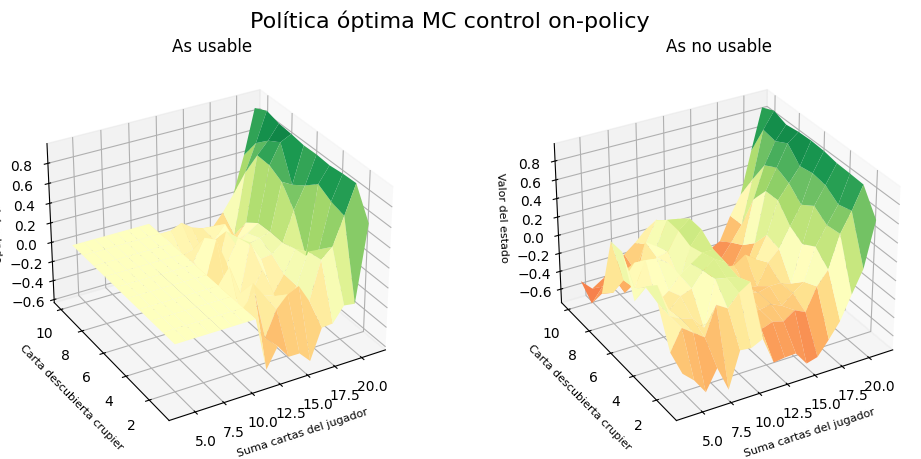

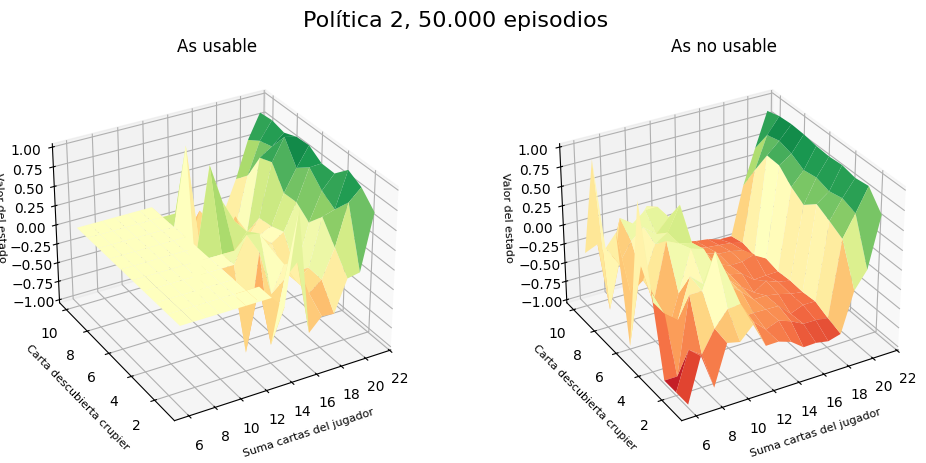

In [26]:
# Comparemos con la politica2 evaluada anteriormente
graficar_funcion_valor(V_MC_on,'Política óptima MC control on-policy')
graficar_funcion_valor(V2_50000,'Política 2, 50.000 episodios')

In [27]:
# Comparación cuantitativa
diferencias = []
for estado, valor in V2_50000.items():
    if estado in V_MC_on:
        diferencia = V_MC_on[estado] - valor
        diferencias.append(diferencia)

print(np.average(diferencias))

0.10326597795141658


En promedio, la política óptima genera un retorno superior (aprox. 10,26%) en comparación con la política de plantarse con 18

###Control "off-policy"

Utiliza dos políticas diferentes:
1. Es la política que define cómo va a interactuar el agente con el entorno "pi"
2. Es la política que se va optimizando "b"

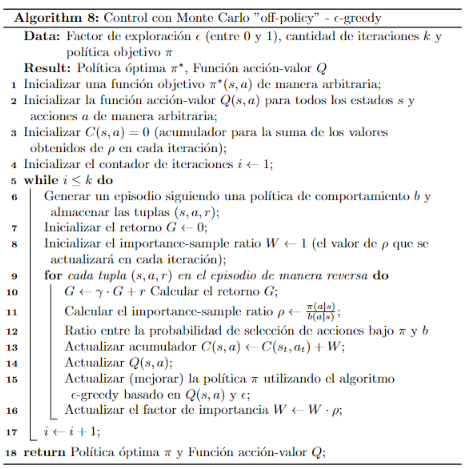

---
**Algorithm 8:** Control con Monte Carlo "off-policy" - $\epsilon$-greedy
---
**Data:** Factor de exploración $\epsilon$ (entre 0 y 1), cantidad de iteraciones $k$ y política objetivo $\pi$  
**Result:** Política óptima $\pi^*$, Función acción-valor $Q$  
***

**1** Inicializar una función objetivo $\pi^*(s, a)$ de manera arbitraria;  
**2** Inicializar la función acción-valor $Q(s, a)$ para todos los estados $s$ y acciones $a$ de manera arbitraria;  
**3** Inicializar $C(s, a) = 0$ (acumulador para la suma de los valores obtenidos de $\rho$ en cada iteración);  
**4** Inicializar el contador de iteraciones $i \leftarrow 1$;  
**5** **while** $i \leq k$ **do**  
> **6** Generar un episodio siguiendo una política de comportamiento $b$ y almacenar las tuplas $(s, a, r)$;  
> **7** Inicializar el retorno $G \leftarrow 0$;  
> **8** Inicializar el importance-sample ratio $W \leftarrow 1$ (el valor de $\rho$ que se actualizará en cada iteración);  
> **9** **for** *cada tupla $(s, a, r)$ en el episodio de manera reversa* **do**  
>> **10** $G \leftarrow \gamma \cdot G + r$ Calcular el retorno $G$;  
>> **11** Calcular el importance-sample ratio $\rho \leftarrow \frac{\pi(a|s)}{b(a|s)}$;  
>> **12** Ratio entre la probabilidad de selección de acciones bajo $\pi$ y $b$  
>> **13** Actualizar acumulador $C(s, a) \leftarrow C(s_t, a_t) + W$;  
>> **14** Actualizar $Q(s, a)$;  
>> **15** Actualizar (mejorar) la política $\pi$ utilizando el algoritmo $\epsilon$-greedy basado en $Q(s, a)$ y $\epsilon$;  
>> **16** Actualizar el factor de importancia $W \leftarrow W \cdot \rho$;  
>
> **17** $i \leftarrow i + 1$;  

**18** **return** Política óptima $\pi$ y Función acción-valor $Q$;  

---

In [28]:
def control_MC_off_policy(env, neps, b, gamma):
    # Inicializar pi, Q y C
    pi = defaultdict(lambda: 1/N_ACCIONES) # la política a optimizar (inicia con valores aleatorios)
    Q = defaultdict(lambda: np.zeros(N_ACCIONES))  #Inicia en cero
    C = defaultdict(lambda: np.zeros(env.action_space.n)) #Acumulador de factores de conversión

    for ep in range(neps):
        # Generar episodio con política de comportamiento (b)
        episodio, T = generar_episodio_control(env, inicializar_politica, b)
        G = 0 # Acumulador retorno
        W = 1.0 # importance-sample ratio (que se actualizará en cada iteración)

        for t in range(T-1,-1,-1):
            St, _, _, At = episodio[t]
            _, Rt1, _, _ = episodio[t+1]

            # Actualizar el retorno
            G = gamma*G + Rt1

            # Actualizar el acumulador C
            C[St][At] += W

            # Actualizar la función Q asociada a "pi"
            Q[St][At] += (W / C[St][At]) * (G - Q[St][At])

            # Actualizar la política de forma codiciosa (greedy)
            A_optima = argmax_aleatorio([Q[St][a] for a in range(N_ACCIONES)])

            for a in range(N_ACCIONES):
                if a == A_optima:
                    pi[(St,a)] = 1
                else:
                    pi[(St,a)] = 0

            # Actualizar importance-sample ratio
            W = W * 1./b[St,At] # Se usa "1" en el numerador porque pi(s,a) es codiciosa

    return Q, pi

In [29]:
# Prueba
b = defaultdict(lambda: 1/N_ACCIONES) # política aleatoria
Q, pi = control_MC_off_policy(env, neps=50000, b=b, gamma=1)

In [30]:
#Veamos los resultados:

# Crear una lista de tuplas con información de probabilidad y valor para cada estado-valor
tabla_resumen = []
for estado, valores_accion in list(Q.items())[:20]:
    probabilidad_accion_0 = pi[(estado, 0)]
    probabilidad_accion_1 = pi[(estado, 1)]
    tabla_resumen.append((estado, probabilidad_accion_0, probabilidad_accion_1, valores_accion[0], valores_accion[1]))

# Encabezados de la tabla
encabezados = ["Estado-Valor", "Probabilidad (Acción 0)", "Probabilidad (Acción 1)", "Valor (Acción 0)", "Valor (Acción 1)"]

# Imprimir la tabla resumen
print("Resumen de Probabilidad y Valor para los Primeros 20 Estado-Valor:")
print(tabulate(tabla_resumen, headers=encabezados, tablefmt="grid"))

Resumen de Probabilidad y Valor para los Primeros 20 Estado-Valor:
+-----------------+---------------------------+---------------------------+--------------------+--------------------+
| Estado-Valor    |   Probabilidad (Acción 0) |   Probabilidad (Acción 1) |   Valor (Acción 0) |   Valor (Acción 1) |
+=================+===========================+===========================+====================+====================+
| (8, 4, False)   |                         0 |                         1 |         -0.387755  |          -0.25     |
+-----------------+---------------------------+---------------------------+--------------------+--------------------+
| (20, 2, False)  |                         1 |                         0 |          0.655678  |          -0.832258 |
+-----------------+---------------------------+---------------------------+--------------------+--------------------+
| (19, 5, False)  |                         1 |                         0 |          0.447674  |          -

In [31]:
# Obtengamos la función estado-valor asociada a esta nueva política
V_MC_off = defaultdict(float)
for estado, acciones in Q.items():
    valor = np.max(acciones)
    V_MC_off[estado] = valor

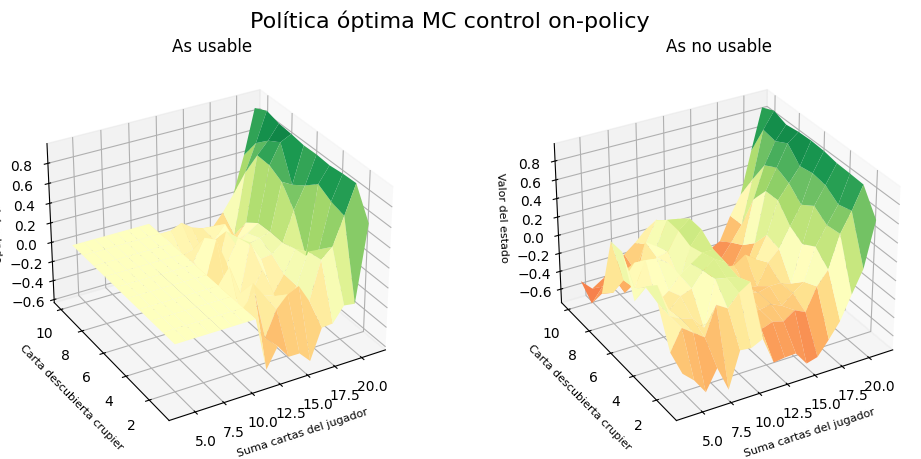

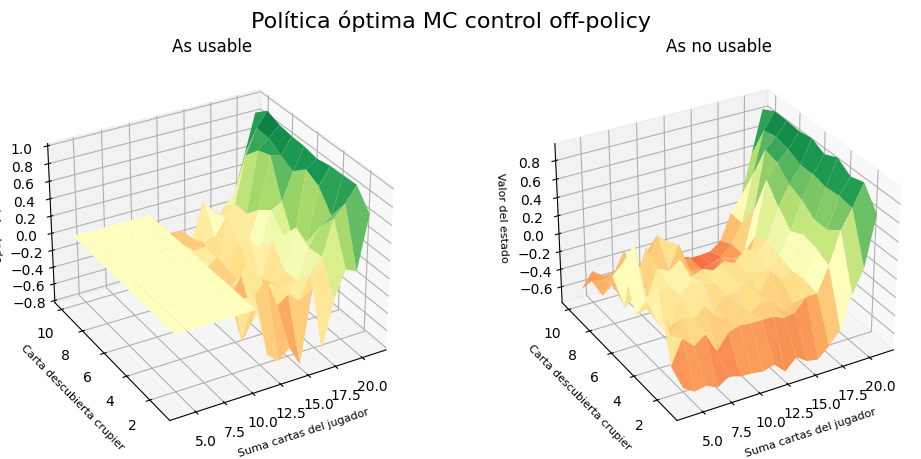

In [32]:
# Y comparemos con la política obtenida con "on-policy" evaluada anteriormente
graficar_funcion_valor(V_MC_on,'Política óptima MC control on-policy')
graficar_funcion_valor(V_MC_off,'Política óptima MC control off-policy')

In [33]:
# Comparación cuantitativa
diferencias = []
for estado, valor in V_MC_off.items():
    if estado in V_MC_on:
        diferencia = V_MC_on[estado] - valor
        diferencias.append(diferencia)

print(np.average(diferencias))

0.077228169126981


Las diferencias entre las dos políticas obtenidas son mínimas (aproximadamente 0.05), pero en esencia los dos métodos entregan resultados similares.